# Metricas de SkLearn


## Metricas para evaluar problemas de Regresion

**Error Cuadratico Medio** (Mean Squared Error : MSE )

$$
\frac{1}{n}\sum_{i = 1}^{n} (y_i  - \hat{y_i})^2
$$

```python
from sklearn import metrics
metrics.mean_squared_error(y_true, y_pred)
```

**Raiz del Error cuadratico medio** (Root Mean Squared Error : RMSE)

$$
\sqrt{\frac{1}{n}\sum_{i = 1}^{n} (y_i  - \hat{y_i})^2}
$$

```
metrics.mean_squared_error(y_true, y_pred, squared = False)
```

**Error Absoluto Medio** (Mean Squared Error :MAE)
$$
\frac{1}{n} \sum_{i = 1}^{n} |y_i - \hat{y_i}|
$$


```
metrics.mean_absolute_error(y_true, y_pred)
```

**Error Absoluto Medio Porcentual** (Mean Absolute Percentage Error : MAPE)
$$
\frac{100\text{\%}}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y_i}}{y_i} \right|
$$


```
metrics.mean_absolute_percentage_error(y_true, y_pred)
```


### Otros indicadores de calidad
  > Coeficiente de determinacion ($R^2$)

  > Error Cuadratico Medio Logaritmico

  > Maximo Error

## Consideraciones Estadisticas y Computacionales

### Robustez y Sensibilidad
  * MAE y MAPE : Robustos a outliers
  * MSE/RMSE : Sensibles a outliers (utiles cuando los errores grandes son criticos)

### Escalabilidad
  * Todas las metricas son computacionalmente eficientes
  * Implementaciones vectorizadas

## Modeo de Regresion Lineal: submodulo linear_model

In [1]:
from sklearn.linear_model import LinearRegression

In [ ]:
help(LinearRegression)

In [ ]:
import sklearn.linear_model

dir(sklearn.linear_model)

'ARDRegression',
 'BayesianRidge',
 'ElasticNet',
 'ElasticNetCV',
 'GammaRegressor',
 'HuberRegressor',
 'Lars',
 'LarsCV',
 'Lasso',
 'LassoCV',
 'LassoLars',
 'LassoLarsCV',
 'LassoLarsIC',
 'LinearRegression',
 'LogisticRegression',
 'LogisticRegressionCV',
 'MultiTaskElasticNet',
 'MultiTaskElasticNetCV',
 'MultiTaskLasso',
 'MultiTaskLassoCV',
 'OrthogonalMatchingPursuit',
 'OrthogonalMatchingPursuitCV',
 'PassiveAggressiveClassifier',
 'PassiveAggressiveRegressor',
 'Perceptron',
 'PoissonRegressor',
 'QuantileRegressor',
 'RANSACRegressor',
 'Ridge',
 'RidgeCV',
 'RidgeClassifier',
 'RidgeClassifierCV',
 'SGDClassifier',
 'SGDOneClassSVM',
 'SGDRegressor',
 'TheilSenRegressor',
 'TweedieRegressor'

## Estrategia para obtener un modelo de regresion lineal
- Definicion de $X$ (todas las variables independiente) e $Y$ (variable dependiente)
- Particonar los datos en subconjunto de entrenamiento (ajustar el modelo) y subconjunto de testeo (calcular indicadores / metricas para medir el poder predictorio del modelo)
- Instanciar la clase a modelar (LinerRegression)
- Ajustar la clase a modelas usando el subconjunto de entrenamiento
- Construir pronosticos de la variable dependiente a partir del modelo y del subconjunto de testeo de las variables independientes
- Calculamos un indicador de calidad (metrica)

# Modelo de Aprendizaje Supervidado para Problemas de Clasificacion:
# Regresion Logistica

In [3]:
# modulos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import  LogisticRegression
from sklearn import metrics

In [7]:
# dataset
df = pd.read_csv('../data/breast-cancer-wisconsin.csv')
df.sample(20)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
146,869691,M,11.800,16.58,78.99,432.0,0.10910,0.17000,0.16590,0.074150,...,26.38,91.93,591.7,0.13850,0.40920,0.45040,0.18650,0.5774,0.10300,NaN
300,892438,M,19.530,18.90,129.50,1217.0,0.11500,0.16420,0.21970,0.106200,...,26.24,171.10,2053.0,0.14950,0.41160,0.61210,0.19800,0.2968,0.09929,NaN
558,925277,B,14.590,22.68,96.39,657.1,0.08473,0.13300,0.10290,0.037360,...,27.27,105.90,733.5,0.10260,0.31710,0.36620,0.11050,0.2258,0.08004,NaN
518,917062,B,12.880,18.22,84.45,493.1,0.12180,0.16610,0.04825,0.053030,...,24.37,99.31,674.7,0.14560,0.29610,0.12460,0.10960,0.2582,0.08893,NaN
150,871001501,B,13.000,20.78,83.51,519.4,0.11350,0.07589,0.03136,0.026450,...,24.11,90.82,616.7,0.12970,0.11050,0.08112,0.06296,0.3196,0.06435,NaN
79,8610908,B,12.860,18.00,83.19,506.3,0.09934,0.09546,0.03889,0.023150,...,24.82,91.88,622.1,0.12890,0.21410,0.17310,0.07926,0.2779,0.07918,NaN
507,91544002,B,11.060,17.12,71.25,366.5,0.11940,0.10710,0.04063,0.042680,...,20.74,76.08,411.1,0.16620,0.20310,0.12560,0.09514,0.2780,0.11680,NaN
275,8911164,B,11.890,17.36,76.20,435.6,0.12250,0.07210,0.05929,0.074040,...,18.99,79.46,472.4,0.13590,0.08368,0.07153,0.08946,0.2220,0.06033,NaN
514,91594602,M,15.050,19.07,97.26,701.9,0.09215,0.08597,0.07486,0.043350,...,28.06,113.80,967.0,0.12460,0.21010,0.28660,0.11200,0.2282,0.06954,NaN
432,908194,M,20.180,19.54,133.80,1250.0,0.11330,0.14890,0.21330,0.125900,...,25.07,146.00,1479.0,0.16650,0.29420,0.53080,0.21730,0.3032,0.08075,NaN


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [9]:
df.drop(columns=['id', 'Unnamed: 32'], inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  569 non-null

In [10]:
# vamos a ver la distribucion de los posibles valores que componen
# la variable dependiente (variable objetivo) "diagnosis"
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [13]:
conteo = df['diagnosis'].value_counts()
porcentaje = df['diagnosis'].value_counts(normalize=True) * 100

print('Conteo de clases:')
print(conteo)
print('\nPorcentaje de clases:')
print(porcentaje.round(2))

Conteo de clases:
diagnosis
B    357
M    212
Name: count, dtype: int64

Porcentaje de clases:
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64


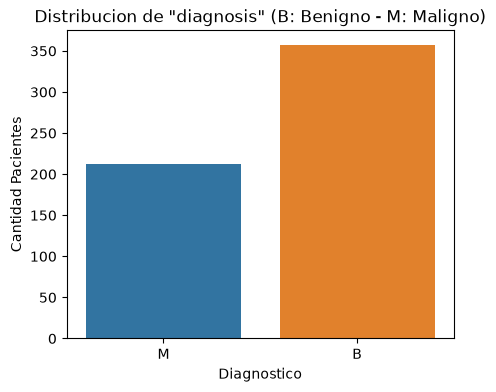

In [15]:
# Visualizacion rapida
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='diagnosis', hue='diagnosis')
plt.title('Distribucion de "diagnosis" (B: Benigno - M: Maligno)')
plt.xlabel('Diagnostico')
plt.ylabel('Cantidad Pacientes')
plt.show()

### Primer Modelo (clasificacion) Regresion Logistica

primer escenario - M: 1  B: 0

In [28]:
# definir las variable dependiente
y = df['diagnosis'].map({'M':1, 'B': 0}) # primer escenario
# y = df['diagnosis'].map{'M':-1, 'B': 1} # segundo escenario
# y = df['diagnosis'].map{'M':0, 'B': 1} # tercer esccenario

# definir las variables independientes
X = df.drop(columns=['diagnosis'])

# particionamos los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# instanciar la clase a modelar
model_base_reglog = LogisticRegression()

# ajustamos el modelo con el subconjunto de datos - train
model_base_reglog.fit(X_train, y_train)

# connstruir  pronosticos para el subconjunto de testeo
y_test_predict = model_base_reglog.predict(X_test)

# Metrica - indicador de calidad
metrics.accuracy_score(y_test, y_test_predict)

c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9210526315789473

In [ ]:
help(LogisticRegression)

In [34]:
# definir las variable dependiente
y = df['diagnosis'].map({'M':1, 'B': 0}) # primer escenario
# y = df['diagnosis'].map{'M':-1, 'B': 1} # segundo escenario
# y = df['diagnosis'].map{'M':0, 'B': 1} # tercer esccenario

# definir las variables independientes
X = df.drop(columns=['diagnosis'])

# particionamos los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# instanciar la clase a modelar
model_base_reglog = LogisticRegression(max_iter=5000)

# ajustamos el modelo con el subconjunto de datos - train
model_base_reglog.fit(X_train, y_train)

# connstruir  pronosticos para el subconjunto de testeo
y_test_predict = model_base_reglog.predict(X_test)

# Metrica - indicador de calidad
metrics.accuracy_score(y_test, y_test_predict)

0.9385964912280702

Segundo escenario  'M': -1, 'B': 1

In [32]:
# definir las variable dependiente
# y = df['diagnosis'].map({'M':1, 'B': 0}) # primer escenario
y = df['diagnosis'].map({'M':-1, 'B': 1}) # segundo escenario
# y = df['diagnosis'].map({'M':0, 'B': 1}) # tercer esccenario

# definir las variables independientes
X = df.drop(columns=['diagnosis'])

# particionamos los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# instanciar la clase a modelar
model_base_reglog = LogisticRegression(max_iter=5000)

# ajustamos el modelo con el subconjunto de datos - train
model_base_reglog.fit(X_train, y_train)

# connstruir  pronosticos para el subconjunto de testeo
y_test_predict = model_base_reglog.predict(X_test)

# Metrica - indicador de calidad
metrics.accuracy_score(y_test, y_test_predict)

0.9649122807017544

Tercer escenario 'M': 0, 'B': 1

In [33]:
# definir las variable dependiente
# y = df['diagnosis'].map({'M':1, 'B': 0}) # primer escenario
# y = df['diagnosis'].map({'M':-1, 'B': 1}) # segundo escenario
y = df['diagnosis'].map({'M':0, 'B': 1}) # tercer esccenario

# definir las variables independientes
X = df.drop(columns=['diagnosis'])

# particionamos los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# instanciar la clase a modelar
model_base_reglog = LogisticRegression(max_iter=5000)

# ajustamos el modelo con el subconjunto de datos - train
model_base_reglog.fit(X_train, y_train)

# connstruir  pronosticos para el subconjunto de testeo
y_test_predict = model_base_reglog.predict(X_test)

# Metrica - indicador de calidad
metrics.accuracy_score(y_test, y_test_predict)

0.9649122807017544

Hiperparametros - parametros de interes de LogisticRegression

In [36]:
# penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'
# C: float, default=1.0 Inverse of regularization strength
# solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'
# l1_ratio: float, default=0.0 The Elastic-Net mixing parameter, with 0 <= l1_ratio <= 1

from sklearn.model_selection import  GridSearchCV

dic_hp_reglog = {
    "penalty": ['l1', 'l2', 'elasticnet', None],
    "C": [0.1, 0.9, 1.1, 9.8, 10.5],
    "solver": ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
    "l1_ratio": [0.1, 0.5, 1]
}

# instanciar la clase LogisticRegression
reg_log = LogisticRegression()

# configurar los hiperparametros
gridf_reglog = GridSearchCV(
    estimator=reg_log,
    param_grid=dic_hp_reglog,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# particionamiento de los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

# ajustamos todos los modelos configurados en la instancia de la clase GridSearchCV
gridf_reglog.fit(X_train, y_train)

c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
750 fits failed out of a total of 1800.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
75 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\Instructor\Desktop\ingswsenati

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 0.9, ...], 'l1_ratio': [0.1, 0.5, ...], 'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs', 'liblinear', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo